# Classification Models

## Discussion questions

Suppose you are developing a classification model to determine whether or not a person has a particular disease (based on symptoms, results of diagnostic tests, family history, risk factors, etc).

1. Explain what "precision" represents in this context.

**Discuss with your partner, and make notes here.**

2. Explain what "recall" represents in this context.

**Discuss with your partner, and make notes here.**

3. Which of the following do you think is a more serious error? It's an opinion question, but choose one and discuss.

- Concluding that a person has the disease if they actually don't have it
- Failing to conclude that a person has the disease if they actually do have it

**Discuss with your partner, and make notes here.**

4. Given your answer to the previous question, which would you prefer to be higher: precision or recall?

**Discuss with your partner, and make notes here.**

5. Suppose you want to achieve higher recall. Should your classification rule be more or less strict about who it predicts to have the disease?

**Discuss with your partner, and make notes here.**

6. What is a downside to your choice in the previous part?

**Discuss with your partner, and make notes here.**

In [1]:
import pandas as pd
import numpy as np

## More wine

The wines data set (https://dlsun.github.io/pods/data/wines.csv ) contains data about the chemical composition of various wines. We'll first use just two features&mdash;fixed acidity and volatile acidity&mdash;to predict the color of the wine (red or white).

In [2]:
df_train = pd.read_csv("https://dlsun.github.io/pods/data/wines.csv")

df_train

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white


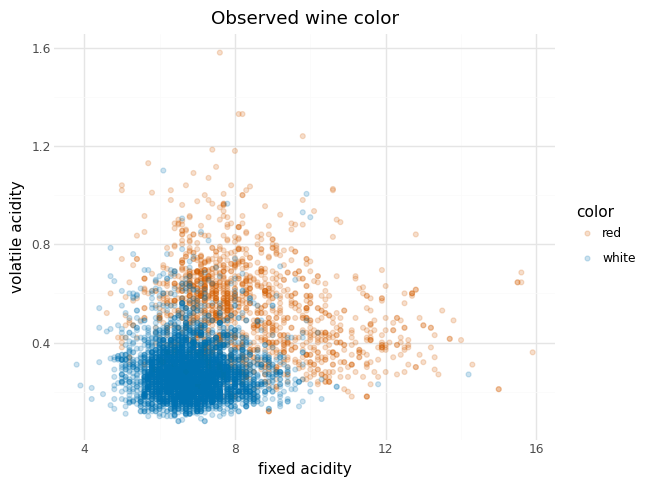

In [3]:
from plotnine import *

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Observed wine color")
    + theme_minimal()
)

1\. Fit a 15-nearest neighbors model for predicting color from fixed acidity and volatile acidity. Don't forget to scale the features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the observed colors.

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import make_column_transformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt

In [12]:
features = ["fixed acidity", "volatile acidity"]

X = df_train[features]
y = df_train["color"]

preprocessor = make_column_transformer(
    (StandardScaler(), ["fixed acidity", "volatile acidity"]), 
    remainder="passthrough"
)
knn = make_pipeline(preprocessor, KNeighborsClassifier(n_neighbors=15))

knn.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardscaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the d

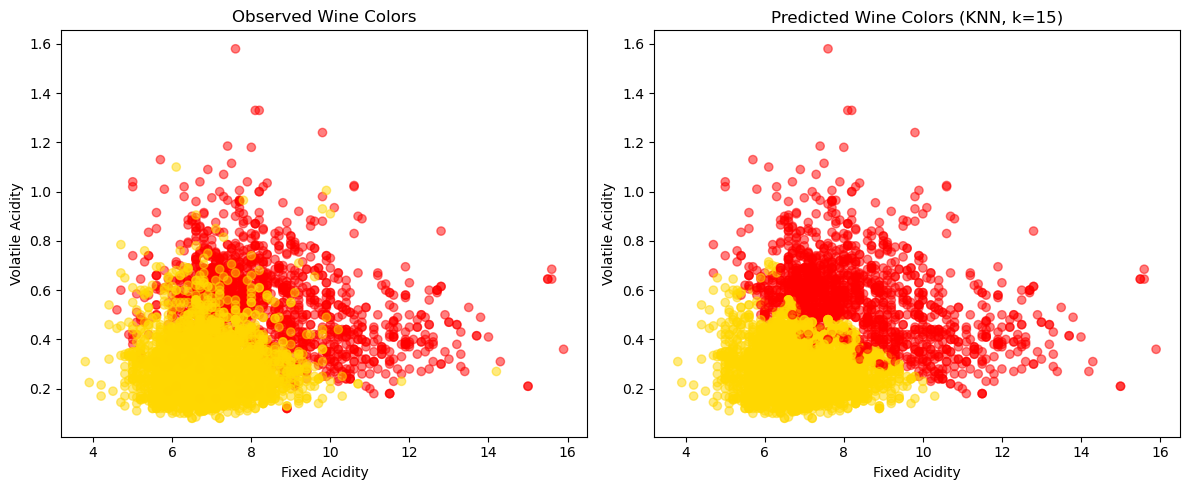

In [14]:
y_pred = knn.predict(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Observed wine colors
axes[0].scatter(
    X["fixed acidity"],
    X["volatile acidity"],
    c=y.map({"red": "red", "white": "gold"}),
    alpha=0.5
)
axes[0].set_title("Observed Wine Colors")
axes[0].set_xlabel("Fixed Acidity")
axes[0].set_ylabel("Volatile Acidity")

# Predicted wine colors
axes[1].scatter(
    X["fixed acidity"],
    X["volatile acidity"],
    c=pd.Series(y_pred).map({"red": "red", "white": "gold"}),
    alpha=0.5
)
axes[1].set_title("Predicted Wine Colors (KNN, k=15)")
axes[1].set_xlabel("Fixed Acidity")
axes[1].set_ylabel("Volatile Acidity")

plt.tight_layout()
plt.show()

2\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score using `macro` scoring.

In [16]:
from sklearn.model_selection import cross_validate

In [18]:
cv_results = cross_validate(
    knn,
    X,
    y,
    cv=10,
    scoring=["precision_macro", "recall_macro", "f1_macro"]
)

print("Precision:", cv_results["test_precision_macro"].mean())
print("Recall:", cv_results["test_recall_macro"].mean())
print("F1 Score:", cv_results["test_f1_macro"].mean())

Precision: 0.882172885523828
Recall: 0.8552999511096255
F1 Score: 0.8643082661209819


3\. Use `GridSearchCV` to fit $k$-nearest neighbors models for $k=1,\ldots, 30$ and use cross validation to estimate the test F1 macro score. Plot the test score versus $k$. Which value of $k$ yields the best score?

In [19]:
from sklearn.model_selection import GridSearchCV

In [20]:
param_grid = {
    "kneighborsclassifier__n_neighbors": range(1, 31)
}

grid_search = GridSearchCV(
    knn,
    param_grid,
    cv=10,
    scoring="f1_macro"
)

grid_search.fit(X, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ighbors=15))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'kneighborsclassifier__n_neighbors': range(1, 31)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3

4\. When the target variable is binary **logistic regression** provides another classification algorithm.

Fit a logistic regression model for predicting wine color from the two features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the predictions from the nearest neighbors classifier.

Note: with regression, you don't need to scale the features (unless you add a penalty). Hint: you basically just need to replace with `KNeighborsClassifier()` with `LogisticRegression()`.

In [21]:
from sklearn.linear_model import LogisticRegression

In [22]:
preprocessor = make_column_transformer(
    (StandardScaler(), ["fixed acidity", "volatile acidity"]), 
    remainder="passthrough"
)
log_model = make_pipeline(preprocessor, LogisticRegression())

log_model.fit(X, y)

y_pred_log = log_model.predict(X)
y_pred_knn = knn.predict(X)

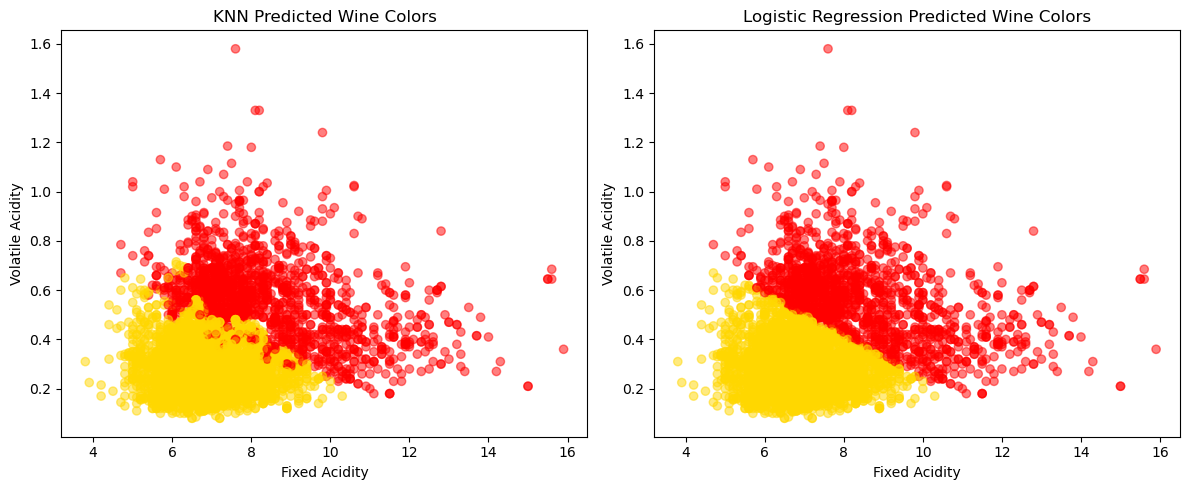

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# KNN predictions
axes[0].scatter(
    X["fixed acidity"],
    X["volatile acidity"],
    c=["red" if color == "red" else "gold" for color in y_pred_knn],
    alpha=0.5
)
axes[0].set_title("KNN Predicted Wine Colors")
axes[0].set_xlabel("Fixed Acidity")
axes[0].set_ylabel("Volatile Acidity")

# Logistic regression predictions
axes[1].scatter(
    X["fixed acidity"],
    X["volatile acidity"],
    c=["red" if color == "red" else "gold" for color in y_pred_log],
    alpha=0.5
)
axes[1].set_title("Logistic Regression Predicted Wine Colors")
axes[1].set_xlabel("Fixed Acidity")
axes[1].set_ylabel("Volatile Acidity")

plt.tight_layout()
plt.show()

5\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring. Compare to the nearest neighbors model.

In [25]:
cv_results_log = cross_validate(
    log_model,
    X,
    y,
    cv=10,
    scoring=["precision_macro", "recall_macro", "f1_macro"]
)

print("Precision:", cv_results_log["test_precision_macro"].mean())
print("Recall:", cv_results_log["test_recall_macro"].mean())
print("F1 Score:", cv_results_log["test_f1_macro"].mean())

Precision: 0.8915854539751831
Recall: 0.8518748060921325
F1 Score: 0.8643286697780195


6\. Now fit a logistic regression model using all of the potential predictors. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [29]:
X_all = df_train.drop(columns=["color"])

log_model_all = LogisticRegression(max_iter=10000)
log_model_all.fit(X_all, y)

cv_results_log_all = cross_validate(
    log_model_all,
    X_all,
    y,
    cv=10,
    scoring=["precision_macro", "recall_macro", "f1_macro"]
)

print("Precision:", cv_results_log_all["test_precision_macro"].mean())
print("Recall:", cv_results_log_all["test_recall_macro"].mean())
print("F1 Score:", cv_results_log_all["test_f1_macro"].mean())

Precision: 0.9843406065482126
Recall: 0.9761826942838716
F1 Score: 0.9800677548297816


7\. Now fit a logistic regression model using all of the potential predictors with a LASSO (`"l1"`) penalty. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [32]:
lasso_log = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l1",
        solver="liblinear",
        max_iter=10000
    )
)

lasso_log.fit(X, y)

cv_results_lasso = cross_validate(
    lasso_log,
    X,
    y,
    cv=10,
    scoring=["precision_macro", "recall_macro", "f1_macro"]
)

print("Precision:", cv_results_lasso["test_precision_macro"].mean())
print("Recall:", cv_results_lasso["test_recall_macro"].mean())
print("F1 Score:", cv_results_lasso["test_f1_macro"].mean())

Precision: 0.8916959216205284
Recall: 0.8521873060921324
F1 Score: 0.8645889083669619


C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
C:\Users\jaxle\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
C:\Users\jaxle\anaconda3\Lib\site-packages\s